In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("food_delivery_orders.csv")

In [3]:
df.head()

,order_id,order_date,city,cuisine,customer_age,customer_type,payment_method,order_value,discount_pct,distance_km,delivery_time_min,rating
0,1001,2025-01-03,Bangalore,North Indian,18,Returning,UPI,317,10,9.2,30,3.9
1,1002,2025-01-04,Bangalore,Fast Food,48,Returning,UPI,219,0,2.0,17,4.6
2,1003,2025-01-04,Mumbai,Biryani,19,Returning,Wallet,592,15,4.4,26,3.5
3,1004,2025-01-05,Hyderabad,Fast Food,18,Returning,Card,565,5,5.9,25,4.0
4,1005,2025-01-06,Bangalore,Biryani,38,Returning,UPI,465,15,8.5,35,3.1


# What is Correlation ?

Correlation is a statistical technique used to measure the strength and direction of the relationship between two numerical variables.

## Types of correlation

- Positive Correlation
- Negative Correlation
- Zero Correlation

A , B 
A increase - B increase -> Positive
A increase - B Decrease -> Negative


In [6]:
cr = df[['order_value',"discount_pct","distance_km","delivery_time_min","rating"]]

In [7]:
cr.head()

,order_value,discount_pct,distance_km,delivery_time_min,rating
0,317,10,9.2,30,3.9
1,219,0,2.0,17,4.6
2,592,15,4.4,26,3.5
3,565,5,5.9,25,4.0
4,465,15,8.5,35,3.1


-1 = 1

In [13]:
cr = cr.corr(method="pearson")

In [ ]:
1,2,3,4,5,6
100,200,300,400,500,600

In [ ]:
1,2,3,4,5,6
100,110,150,170,200

1 ,2, 3,4, 5

In [16]:
cr

,order_value,discount_pct,distance_km,delivery_time_min,rating
order_value,1.000000,0.047558,0.064875,0.043054,-0.014024
discount_pct,0.047558,1.000000,-0.039559,-0.032277,-0.027586
distance_km,0.064875,-0.039559,1.000000,0.877519,-0.482769
delivery_time_min,0.043054,-0.032277,0.877519,1.000000,-0.558438
rating,-0.014024,-0.027586,-0.482769,-0.558438,1.000000


## Correlation is not Causation.

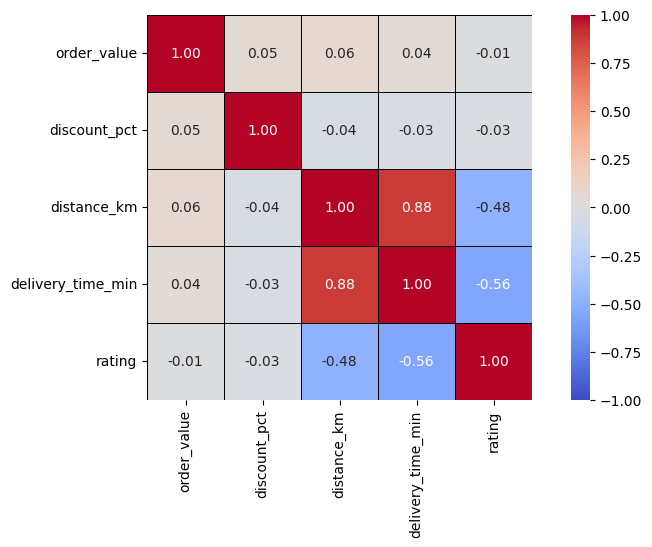

In [27]:
plt.figure(figsize=(10,5))
sns.heatmap(
    cr,
    annot=True,
    cbar=True,
    square=True,
    linewidths=0.5,
    linecolor='black',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)
plt.show()

In [30]:
cr

,order_value,discount_pct,distance_km,delivery_time_min,rating
order_value,1.000000,0.047558,0.064875,0.043054,-0.014024
discount_pct,0.047558,1.000000,-0.039559,-0.032277,-0.027586
distance_km,0.064875,-0.039559,1.000000,0.877519,-0.482769
delivery_time_min,0.043054,-0.032277,0.877519,1.000000,-0.558438
rating,-0.014024,-0.027586,-0.482769,-0.558438,1.000000


In [38]:
tr = np.triu(cr)
tr

array([[ 1.        ,  0.04755803,  0.06487515,  0.04305427, -0.01402417],
       [ 0.        ,  1.        , -0.03955914, -0.03227683, -0.02758605],
       [ 0.        ,  0.        ,  1.        ,  0.87751883, -0.48276923],
       [ 0.        ,  0.        ,  0.        ,  1.        , -0.55843838],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  1.        ]])

In [31]:
np.tril(cr)

array([[ 1.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.04755803,  1.        ,  0.        ,  0.        ,  0.        ],
       [ 0.06487515, -0.03955914,  1.        ,  0.        ,  0.        ],
       [ 0.04305427, -0.03227683,  0.87751883,  1.        ,  0.        ],
       [-0.01402417, -0.02758605, -0.48276923, -0.55843838,  1.        ]])

In [36]:
mask = np.tril(np.ones_like(cr,dtype=bool))
mask

array([[ True, False, False, False, False],
       [ True,  True, False, False, False],
       [ True,  True,  True, False, False],
       [ True,  True,  True,  True, False],
       [ True,  True,  True,  True,  True]])

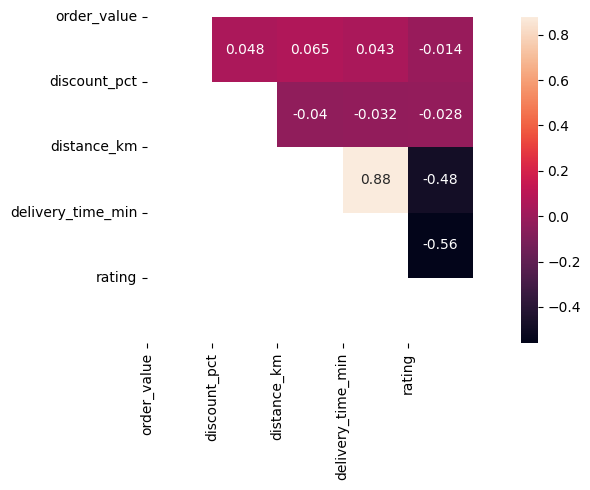

In [46]:
plt.figure(figsize=(10,5))
sns.heatmap(tr,
            annot=True,
            mask=mask,
            square=True)
plt.xticks([0,1,2,3,4],['order_value',"discount_pct","distance_km","delivery_time_min","rating"],rotation=90)
plt.yticks([0,1,2,3,4],['order_value',"discount_pct","distance_km","delivery_time_min","rating"],rotation=0)
plt.tight_layout()
plt.show()

In [49]:
pvt = df.pivot_table(values="order_value",index="cuisine",columns="payment_method",aggfunc="sum")

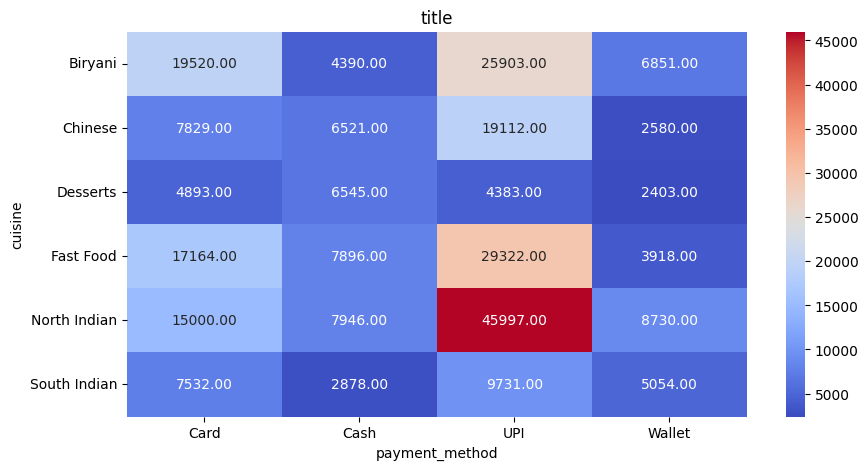

In [55]:
plt.figure(figsize=(10,5))

sns.heatmap(pvt,annot=True,fmt=".2f",cmap="coolwarm")
plt.title("title")
plt.show()

##  Functions given by seaborn

Figure Level - pairplot, jointplot, relplot, displot, catplot

Axes Level - barplot, lineplot, heatmap, pie
 






<Axes: xlabel='cuisine', ylabel='order_value'>

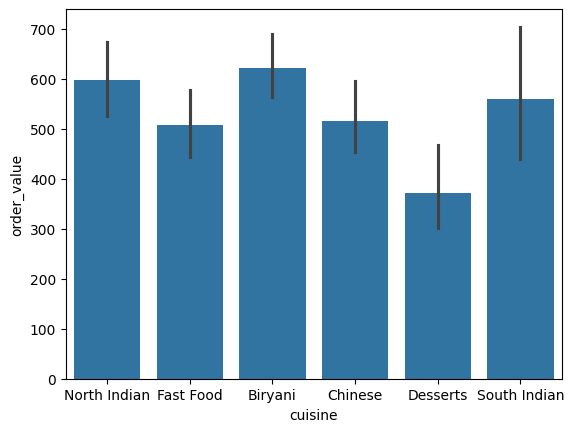

In [ ]:
sns.barplot(data=df,x="cuisine",y="order_value") # Axes level


# Figure level plot

## pairplot

<Figure size 1200x500 with 0 Axes>

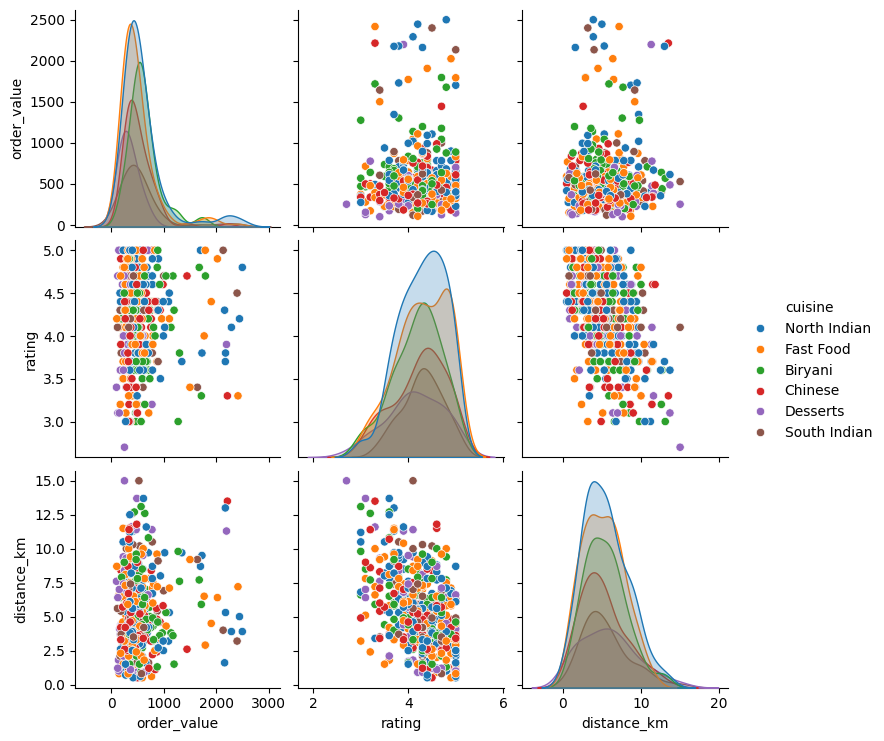

In [69]:
plt.figure(figsize=(12,5))
sns.pairplot(df[['order_value',"rating","distance_km","cuisine"]],kind="scatter",diag_kind="kde",hue="cuisine")
plt.show()

## jointplot

<Figure size 1000x500 with 0 Axes>

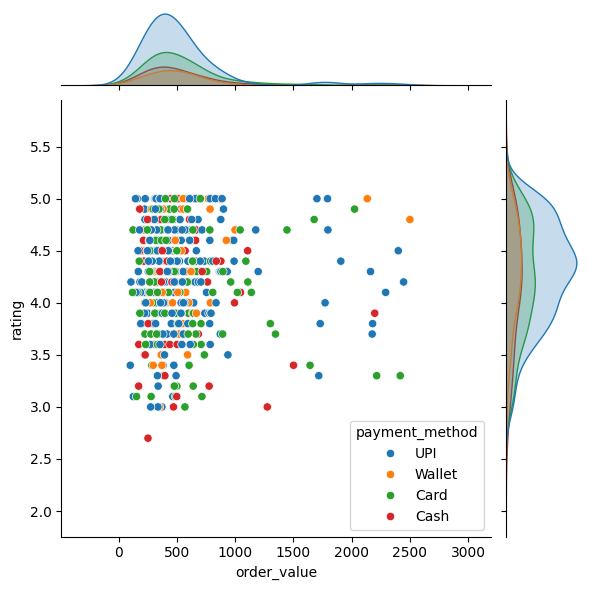

In [ ]:
plt.figure(figsize=(10,5))
sns.jointplot(df,x="order_value",y="rating",hue="payment_method",kind="scatter",)

## relplot

<Figure size 1000x500 with 0 Axes>

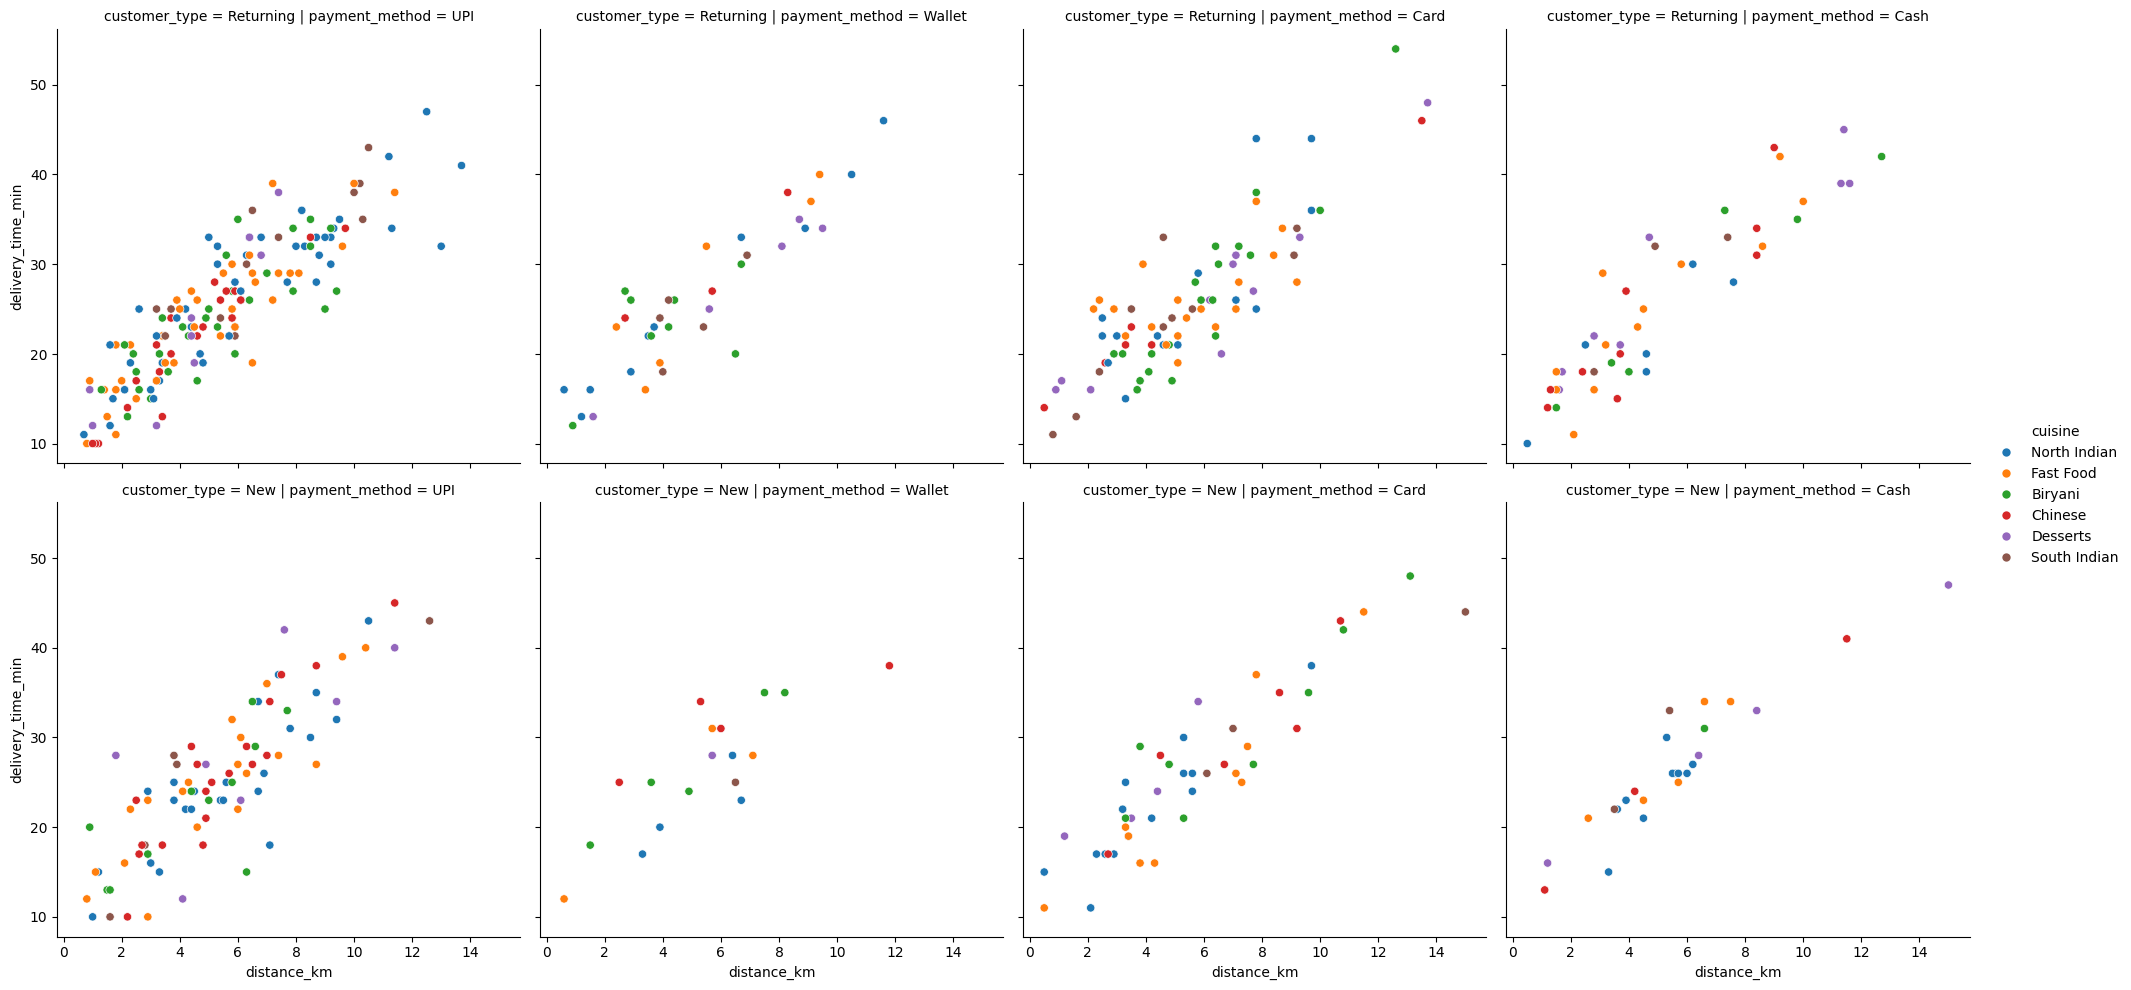

In [88]:
plt.figure(figsize=(10,5))
sns.relplot(data=df,y="delivery_time_min",x="distance_km",col="payment_method",row="customer_type",kind="scatter",hue="cuisine")
plt.show()

# displot

<Figure size 1000x500 with 0 Axes>

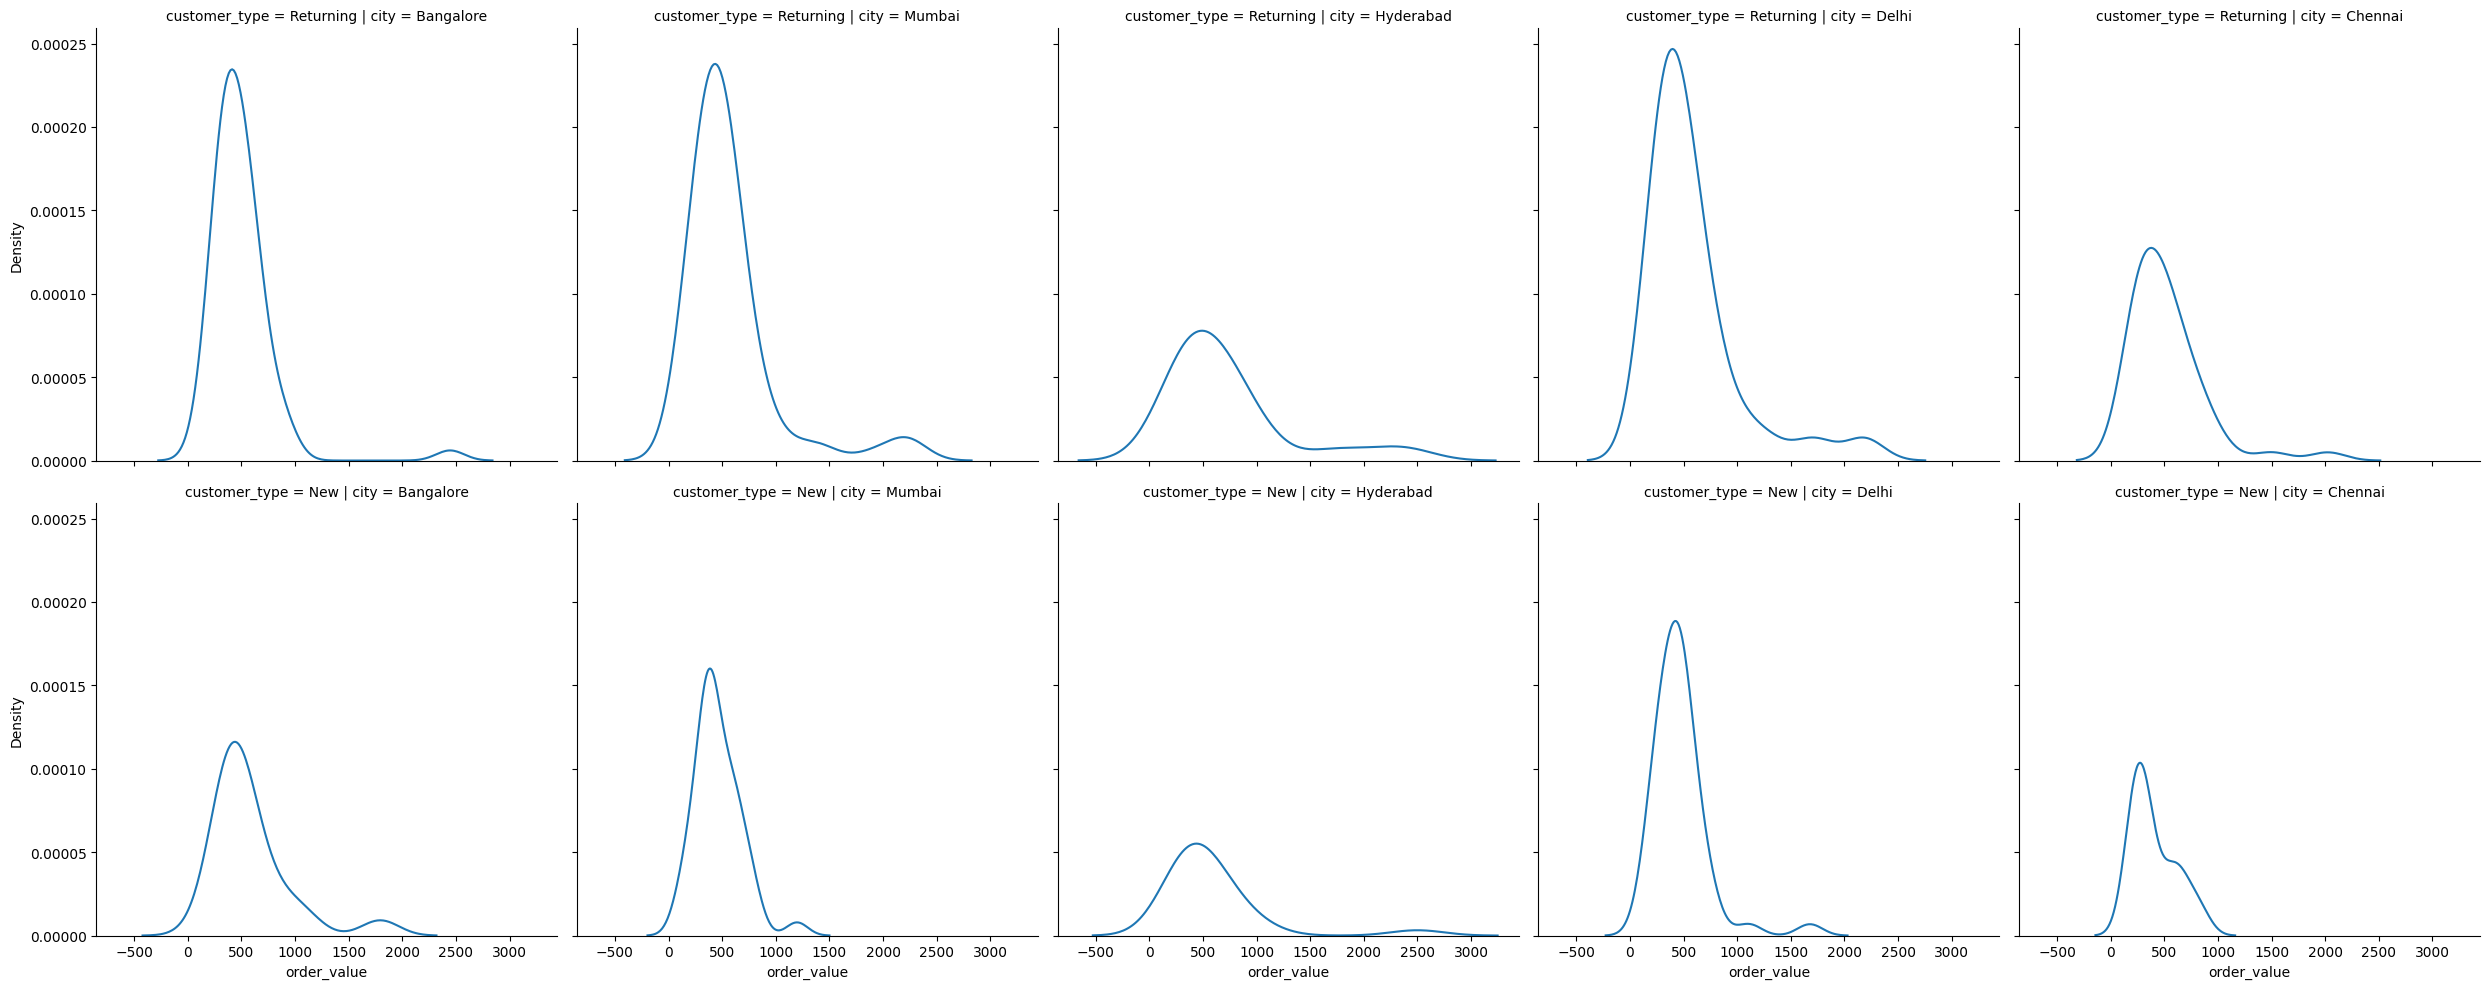

In [98]:
plt.figure(figsize=(10,5))
sns.displot(data=df,x="order_value",row="customer_type",col="city",kind="kde")
plt.show()

## catplot

<Figure size 1600x900 with 0 Axes>

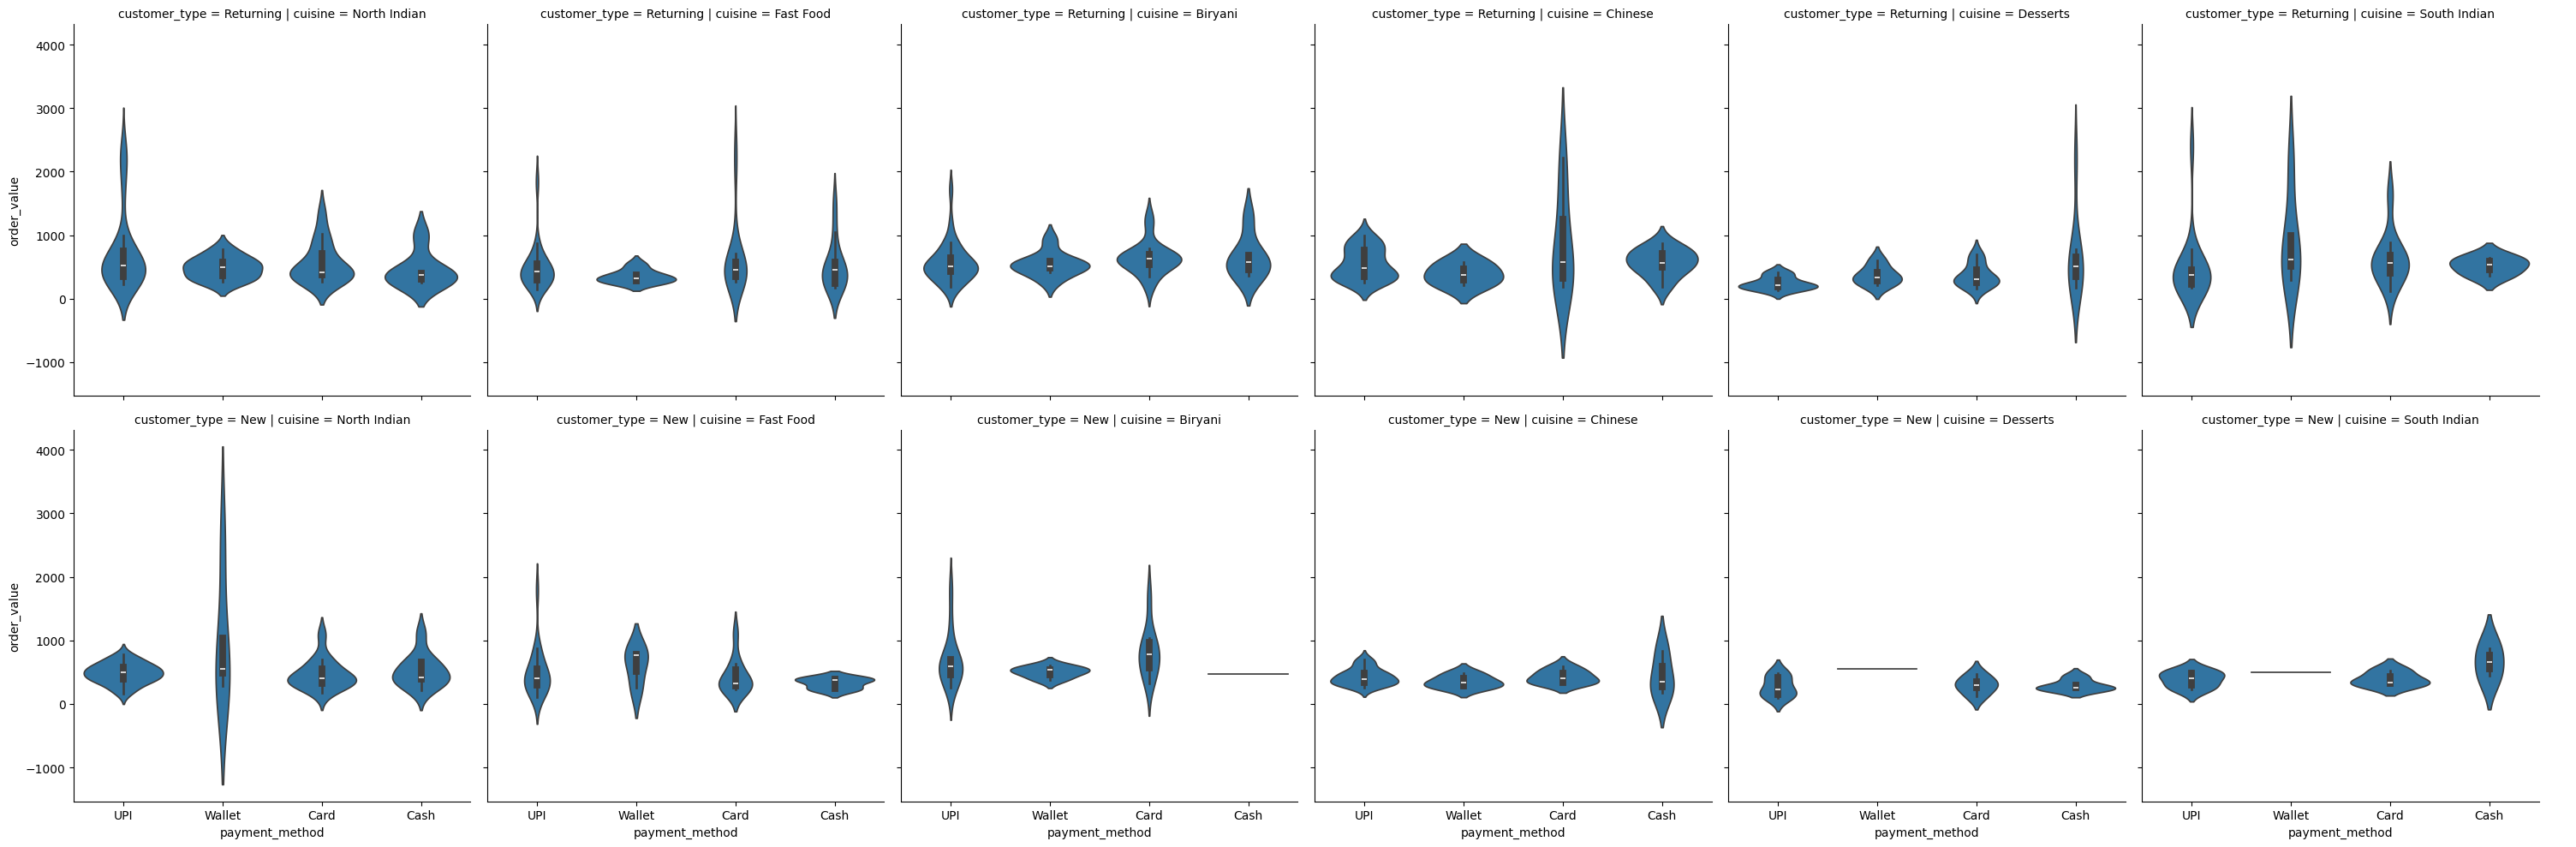

In [107]:
plt.figure(figsize=(16,9))
sns.catplot(data=df,y="order_value",x="payment_method",kind="violin",col="cuisine",row="customer_type")
plt.show()

# FacetGrid

<Figure size 1600x900 with 0 Axes>

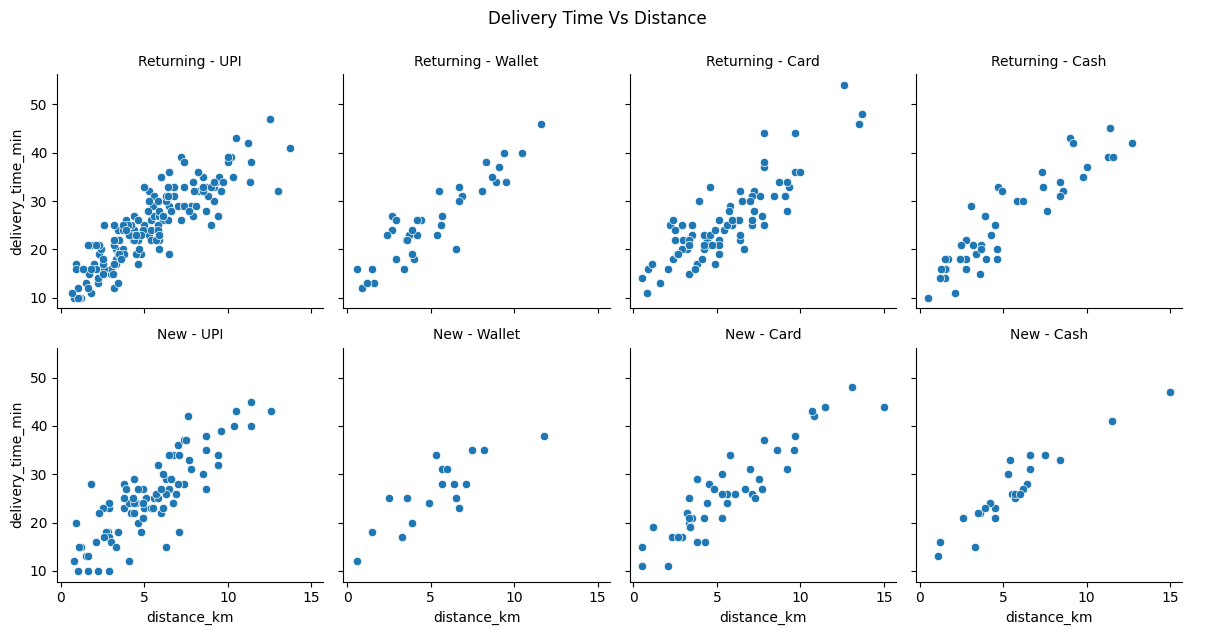

In [114]:
plt.figure(figsize=(16,9))
pt = sns.FacetGrid(df,row="customer_type",col="payment_method")
pt.map(sns.scatterplot,"distance_km","delivery_time_min")
pt.add_legend()
pt.set_titles("{row_name} - {col_name}")
pt.figure.suptitle("Delivery Time Vs Distance ",y=1.05)
plt.show()

<Figure size 1000x500 with 0 Axes>

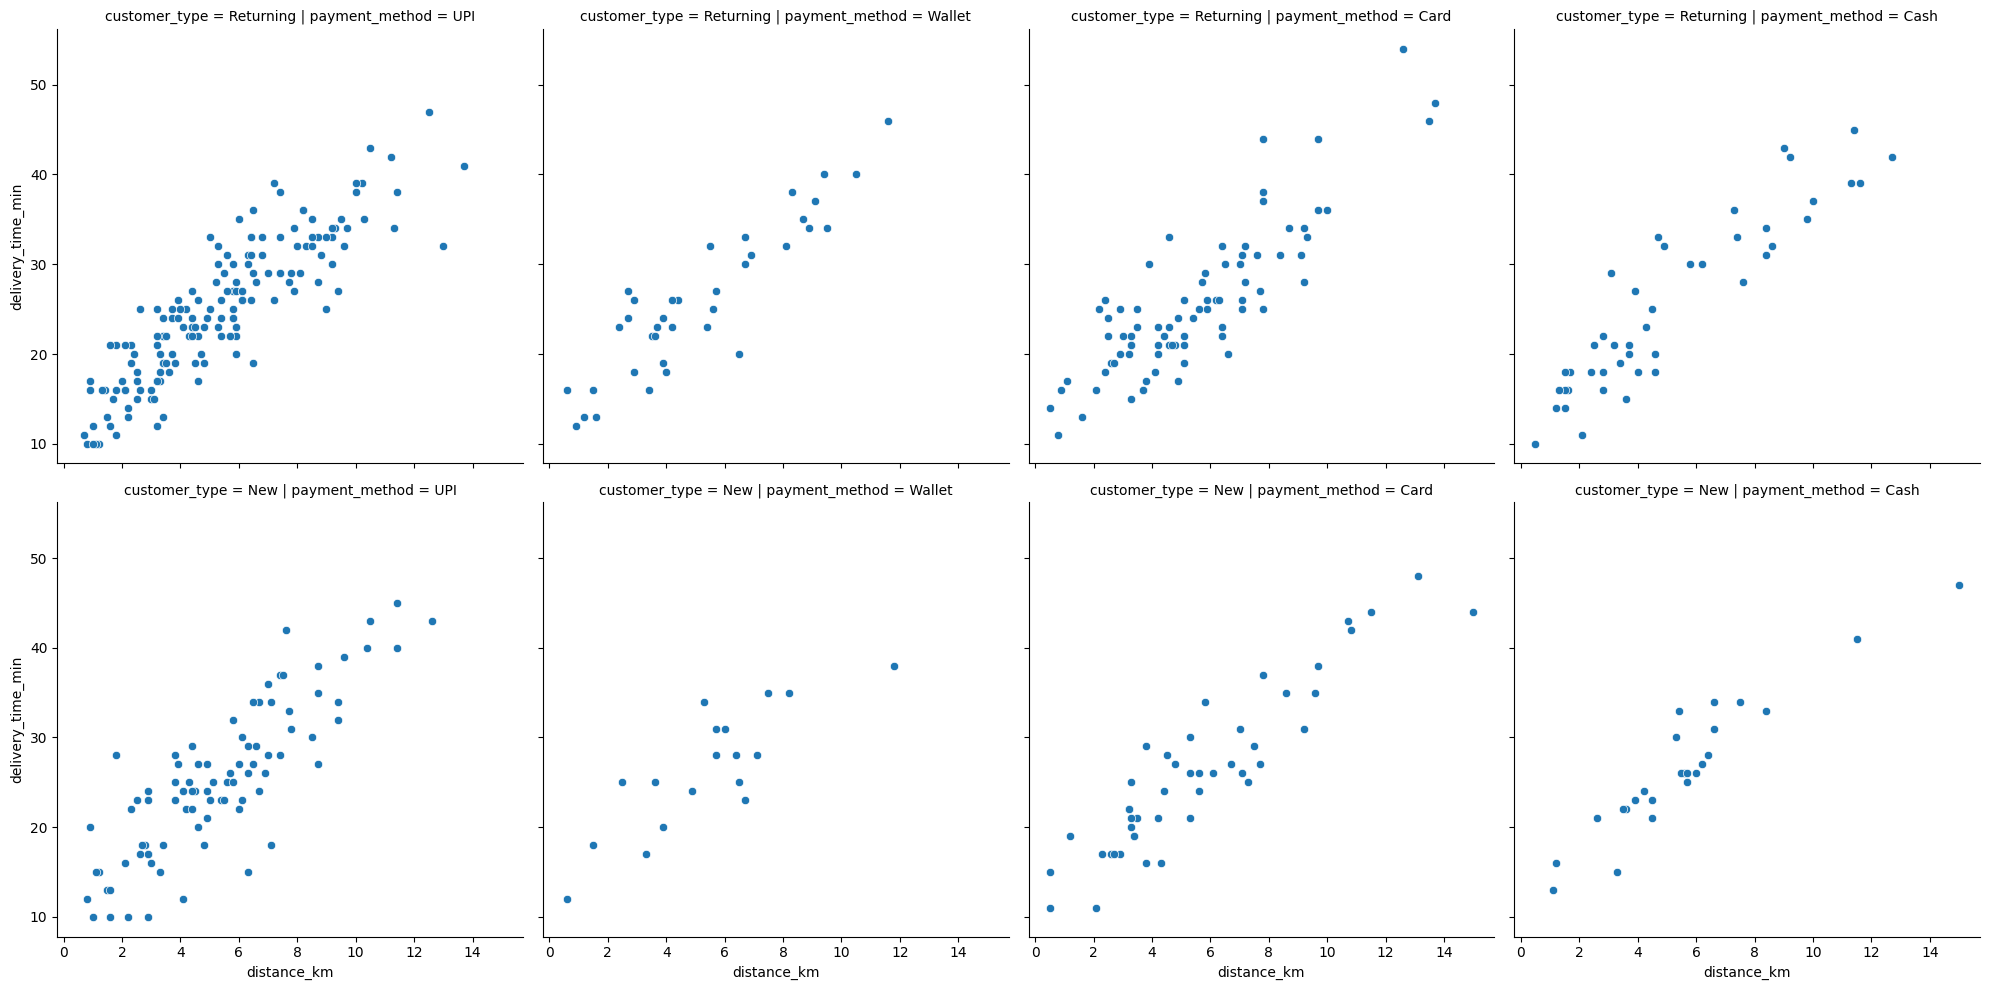

In [112]:
plt.figure(figsize=(10,5))
sns.relplot(data=df,y="delivery_time_min",x="distance_km",col="payment_method",row="customer_type",kind="scatter")
plt.show()